# Module 2 — Unsupervised Tectonic Pattern Discovery

**Input:** Module 1 Base splits (`train_base.parquet`, `val_base.parquet`, `test_base.parquet`)
**Output:** Augmented splits (`*_augmented.parquet`) + fitted clusterers (`dbscan_model.joblib`, `gmm_model.joblib`) + validation report

What this notebook does, in order:
1. **Setup** — detect Colab vs local, set folder paths.
2. **Load & check** the Base splits (falls back to *mock* data if Module 1 hasn't produced them yet).
3. **DBSCAN, two ways** — 3D ECEF (Euclidean, km, depth-aware) and spherical (haversine, surface only). `eps` = k-distance knee, nudged into the 5–20 % noise band.
4. **Out-of-sample assignment** — DBSCAN is fit on *train only*; val/test points are assigned to the nearest core point's cluster if within `eps`.
5. **Pick the better DBSCAN variant** by silhouette score.
6. **GMM (EM)** on ECEF + sensor PCA, sweep K, pick K* by BIC.
7. **Evaluate** (silhouette, Davies-Bouldin, maps) and write a report.
8. **Build & export** the Augmented dataset.

Run with **Runtime → Restart and run all** (Colab) or **Restart Kernel and Run All Cells** (Jupyter).

## 0. Environment setup
Detects whether we are in Google Colab or running locally and sets folder paths accordingly (from `module2/TODO.md` §3.1, plus report folders). Like Module 1, shared datasets live in the repo-root `data/` folder in both modes.

In [1]:
# Cell 1: Colab / Local Environment Setup
import os, sys

IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print("Running in Google Colab. Setting up workspace...")
    from google.colab import drive
    drive.mount('/content/drive')

    REPO_NAME = "seismic-fault-impact"
    REPO_PATH = f"/content/{REPO_NAME}"
    if not os.path.exists(REPO_PATH):
        !git clone https://github.com/Tulip0648/seismic-fault-impact.git {REPO_PATH}

    %cd {REPO_PATH}/module2
    !pip install -r ../requirements.txt -q
    DATA_BASE_DIR = "../data/processed"
    DATA_AUG_DIR = "../data/augmented"
    ARTIFACTS_DIR = "./artifacts"
else:
    print("Running locally.")
    # Same layout as Module 1: shared data lives in the repo-root data/ folder
    DATA_BASE_DIR = "../data/processed"
    DATA_AUG_DIR = "../data/augmented"
    ARTIFACTS_DIR = "./artifacts"

REPORTS_DIR = "./reports"
print(f"Base data path: {DATA_BASE_DIR}")
print(f"Augmented data path: {DATA_AUG_DIR}")

Running locally.
Base data path: ../data/processed
Augmented data path: ../data/augmented


## 0b. Imports & configuration
Every tunable number lives here so you can change behaviour without hunting through the notebook.

In [2]:
import json
import warnings

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# --- General ---
RANDOM_STATE = 42                 # same seed as Module 1 -> reproducible everywhere
EARTH_RADIUS_KM = 6371.0          # must match Module 1's ECEF radius
SPLITS = ["train", "val", "test"]

# --- Column groups (from the Module 1 Base contract) ---
ECEF_COLS = ["x_ecef", "y_ecef", "z_ecef"]   # 3D position in km (depth-aware)
SPHERE_COLS = ["lat_rad", "lon_rad"]         # (lat, lon) order is what sklearn's haversine expects
TARGET_COLS = ["alert", "mmi"]               # must NEVER be fed to a clusterer

# --- DBSCAN ---
MIN_SAMPLES = 10                              # spec suggests 10-20; smaller = more, smaller faults
NOISE_BAND = (0.05, 0.20)                     # spec: 5-20% of events should be background noise
EPS_SEARCH_FACTORS = np.geomspace(0.25, 4.0, 41)  # eps candidates = knee * these (index 20 == 1.0)
FORCE_DBSCAN_VARIANT = None                   # None = auto-pick; or "ecef" / "haversine" to override

# --- GMM ---
GMM_K_GRID = [5, 10, 15, 20, 25, 30, 40]      # spec's K sweep
GMM_COVARIANCE = "full"                       # each component gets its own tilted ellipsoid
GMM_N_INIT = 3                                # EM restarts per K; best one is kept
GMM_MAX_ITER = 500
GMM_REG_COVAR = 0.05                          # added to every covariance diagonal; stops components collapsing
                                              # onto a few training points (sklearn default 1e-6 overfit badly
                                              # on the real data: train/val log-likelihood gap ~2.4 -> ~0.4)
GMM_MAX_TRAIN_VAL_GAP = 1.0                   # warn if mean log-lik on train exceeds val by more than this

# --- Evaluation ---
SILHOUETTE_SAMPLE = 5000                      # silhouette is O(n^2); subsample above this

# The two DBSCAN "spaces" we compare. km_per_unit converts the space's distance unit to km.
VARIANTS = {
    "ecef":      {"cols": ECEF_COLS,   "metric": "euclidean", "algorithm": "auto",      "km_per_unit": 1.0},
    "haversine": {"cols": SPHERE_COLS, "metric": "haversine", "algorithm": "ball_tree", "km_per_unit": EARTH_RADIUS_KM},
}

plt.rcParams["figure.dpi"] = 110
print("Config loaded.")

Config loaded.


## 1. Data loading & spatial inspection

### 1a. Mock data fallback
Module 1 may not have produced its files yet. `make_mock_base_splits` creates **fake** Base splits with the exact Module 1 column contract: quakes scattered along fake fault lines (some shallow, some dipping "slabs" that get deeper), plus uniform background quakes. This is *only* so this notebook can be built and tested — mock results mean nothing scientifically.

In [3]:
def geodetic_to_ecef(lat_deg, lon_deg, depth_km, R=EARTH_RADIUS_KM):
    """Same formula as Module 1: (lat, lon, depth) -> (x, y, z) in km."""
    phi, lam = np.radians(lat_deg), np.radians(lon_deg)
    r = R - depth_km
    return r * np.cos(phi) * np.cos(lam), r * np.cos(phi) * np.sin(lam), r * np.sin(phi)


def make_mock_base_splits(n_events=4000, n_faults=12, background_frac=0.10, seed=RANDOM_STATE):
    """Fake Base splits matching the Module 1 contract. FOR TESTING ONLY."""
    rng = np.random.default_rng(seed)
    n_bg = int(n_events * background_frac)
    per_fault = rng.multinomial(n_events - n_bg, np.ones(n_faults) / n_faults)

    lats, lons, depths = [], [], []
    for n in per_fault:
        lat0, lon0 = rng.uniform(-55, 55), rng.uniform(-180, 180)   # fault centre
        az = rng.uniform(0, np.pi)                                   # fault strike direction
        length = rng.uniform(400, 1500)                              # km
        along = rng.uniform(-length / 2, length / 2, n)              # position along the fault
        across = rng.normal(0, 15, n)                                # scatter perpendicular to it
        if rng.random() < 0.4:                                       # dipping slab: deeper = further across
            depth = rng.uniform(10, 400, n)
            across = across + depth / np.tan(np.radians(60))
        else:                                                        # shallow crustal fault
            depth = np.abs(rng.normal(15, 8, n)) + 1
        north = along * np.cos(az) - across * np.sin(az)
        east = along * np.sin(az) + across * np.cos(az)
        lats.append(lat0 + north / 111.2)
        lons.append(lon0 + east / (111.2 * np.cos(np.radians(lat0))))
        depths.append(depth)

    # background tremors: uniform over the sphere's surface, mostly shallow
    lats.append(np.degrees(np.arcsin(rng.uniform(-1, 1, n_bg))))
    lons.append(rng.uniform(-180, 180, n_bg))
    depths.append(np.clip(rng.exponential(40, n_bg), 1, 700))

    lat = np.clip(np.concatenate(lats), -89.9, 89.9)
    lon = (np.concatenate(lons) + 180) % 360 - 180
    depth = np.concatenate(depths)
    n = len(lat)

    df = pd.DataFrame({"event_id": [f"mock{i:05d}" for i in range(n)],
                       "latitude": lat, "longitude": lon, "depth": depth})
    df["lat_rad"], df["lon_rad"] = np.radians(lat), np.radians(lon)
    df["x_ecef"], df["y_ecef"], df["z_ecef"] = geodetic_to_ecef(lat, lon, depth)
    df["mag"] = 4.5 + rng.exponential(0.6, n)
    mag_type = rng.choice(["mb", "mww", "ml"], size=n, p=[0.4, 0.5, 0.1])
    for t in ["mb", "mww", "ml"]:
        df[f"magType_{t}"] = (mag_type == t).astype("float64")
    for c in ["nst", "gap", "dmin", "rms", "horizontalError", "depthError", "magError"]:
        df[c] = rng.normal(0, 1, n)            # pretend: already imputed + scaled
    for i in (1, 2, 3):
        df[f"pca_sensor_{i}"] = rng.normal(0, 1, n)
    df["mmi"] = np.clip(1.6 * df["mag"] - 0.004 * depth - 3.5 + rng.normal(0, 0.7, n), 1, 10)
    df["alert"] = pd.cut(df["mmi"], [-np.inf, 5, 6.5, 8, np.inf],
                         labels=["green", "yellow", "orange", "red"]).astype(str)

    # 70 / 15 / 15 stratified split, same recipe Module 1 uses
    idx = np.arange(n)
    trval, te = train_test_split(idx, test_size=0.15, stratify=df["alert"], random_state=seed)
    tr, va = train_test_split(trval, test_size=0.15 / 0.85, stratify=df["alert"].iloc[trval], random_state=seed)
    return {s: df.iloc[ix].reset_index(drop=True) for s, ix in zip(SPLITS, [tr, va, te])}

### 1b. Load the Base splits
If all three Module 1 files exist they are used. Otherwise mock data is generated **and every output is redirected into a `mock/` subfolder** so fake results can never be mistaken for real ones.

In [4]:
def load_base_splits(base_dir):
    """Returns ({split: DataFrame}, using_mock: bool)."""
    paths = {s: os.path.join(base_dir, f"{s}_base.parquet") for s in SPLITS}
    missing = [p for p in paths.values() if not os.path.exists(p)]
    if missing:
        warnings.warn(f"Module 1 Base files not found ({missing}). USING MOCK DATA - results are NOT real.")
        return make_mock_base_splits(), True
    return {s: pd.read_parquet(p) for s, p in paths.items()}, False


splits, USING_MOCK = load_base_splits(DATA_BASE_DIR)

if USING_MOCK:
    DATA_AUG_DIR = os.path.join(DATA_AUG_DIR, "mock")
    ARTIFACTS_DIR = os.path.join(ARTIFACTS_DIR, "mock")
    REPORTS_DIR = os.path.join(REPORTS_DIR, "mock")
    print("*** MOCK MODE: outputs go to .../mock/ folders ***")

FIG_DIR = os.path.join(REPORTS_DIR, "figures")
for d in (DATA_AUG_DIR, ARTIFACTS_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

for s, df in splits.items():
    print(f"{s:5s}: {df.shape[0]:6d} rows x {df.shape[1]} cols")

train:   3105 rows x 46 cols
val  :    665 rows x 46 cols
test :    666 rows x 46 cols


### 1c. Contract check
Fail loudly *now* if Module 1's output doesn't match what we expect, instead of failing mysteriously later.
`PCA_COLS` is detected rather than hard-coded, because Module 1 picks 2–4 components based on the 85 % variance rule.

In [5]:
def check_base_contract(splits):
    """Asserts required columns exist, coords have no NaNs, splits don't share events. Returns PCA column names."""
    required = ["event_id", "depth"] + SPHERE_COLS + ECEF_COLS + TARGET_COLS
    pca_cols = sorted([c for c in splits["train"].columns if c.startswith("pca_sensor_")],
                      key=lambda c: int(c.rsplit("_", 1)[1]))
    assert pca_cols, "No pca_sensor_* columns found in train_base."
    for name, df in splits.items():
        missing = [c for c in required + pca_cols if c not in df.columns]
        assert not missing, f"{name}: missing columns {missing}"
        n_nan = int(df[SPHERE_COLS + ECEF_COLS + pca_cols].isna().sum().sum())
        assert n_nan == 0, f"{name}: {n_nan} NaNs in clustering columns"
        assert df["event_id"].is_unique, f"{name}: duplicate event_id"
    ids = {s: set(df["event_id"]) for s, df in splits.items()}
    for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
        assert not (ids[a] & ids[b]), f"Leakage: {a} and {b} share event_ids"
    return pca_cols


PCA_COLS = check_base_contract(splits)
train = splits["train"]
print("Contract OK. PCA columns:", PCA_COLS)
train[["latitude", "longitude", "depth"] + ECEF_COLS].describe().round(1)

Contract OK. PCA columns: ['pca_sensor_1', 'pca_sensor_2', 'pca_sensor_3']


,latitude,longitude,depth,x_ecef,y_ecef,z_ecef
count,3105.0,3105.0,3105.0,3105.0,3105.0,3105.0
mean,-0.1,17.5,61.6,-2132.7,701.4,-25.3
std,32.8,128.3,125.7,3405.3,3595.6,3204.5
min,-69.8,-180.0,0.0,-6265.0,-6359.8,-5965.0
25%,-22.9,-104.4,10.0,-5235.3,-1420.9,-2452.7
50%,-4.0,51.1,12.5,-3312.0,804.4,-446.1
75%,26.9,139.9,41.5,799.1,3809.5,2866.7
max,85.7,180.0,670.8,6318.9,6350.9,6343.3


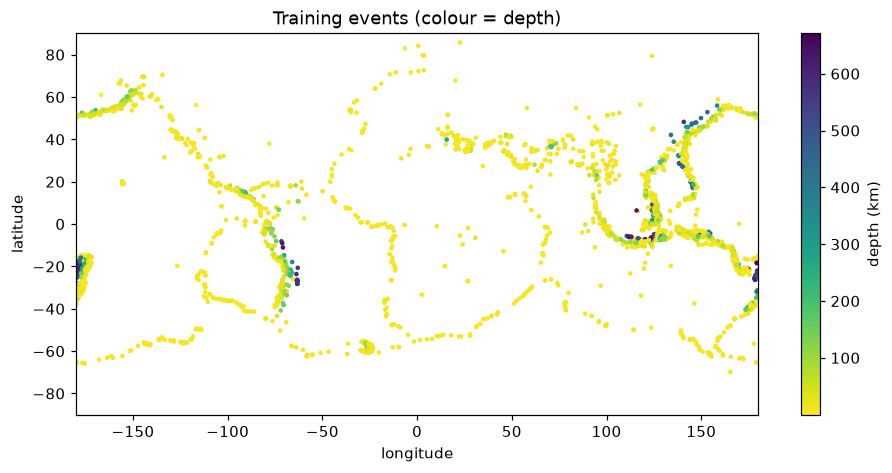

In [6]:
# Quick look: where are the training earthquakes? (colour = depth)
fig, ax = plt.subplots(figsize=(10, 4.5))
sc = ax.scatter(train["longitude"], train["latitude"], c=train["depth"], s=4, cmap="viridis_r")
plt.colorbar(sc, ax=ax, label="depth (km)")
ax.set(xlabel="longitude", ylabel="latitude", title="Training events (colour = depth)", xlim=(-180, 180), ylim=(-90, 90))
fig.savefig(os.path.join(FIG_DIR, "train_events_map.png"), bbox_inches="tight")
plt.show()

## 2. DBSCAN in two spaces

| Variant | Columns | Distance | Sees depth? |
|---|---|---|---|
| `ecef` | `x_ecef, y_ecef, z_ecef` | straight-line (Euclidean) in km | **yes** |
| `haversine` | `lat_rad, lon_rad` | great-circle on the surface (radians × 6371 = km) | no |

Everything is expressed in **km** for humans; `km_per_unit` converts to/from each space's native unit.

### 2a. Helper functions

In [7]:
def to_space(df, variant):
    """Pull the columns a variant clusters on, as a float numpy array."""
    return df[VARIANTS[variant]["cols"]].to_numpy(dtype=float)


def k_distance_km(X, variant, k=MIN_SAMPLES):
    """Sorted distance (km) from every point to its k-th nearest neighbour (the point itself counts as #1,
    exactly like DBSCAN's min_samples). The 'knee' of this curve is a natural eps."""
    v = VARIANTS[variant]
    nn = NearestNeighbors(n_neighbors=k, metric=v["metric"], algorithm=v["algorithm"]).fit(X)
    dist, _ = nn.kneighbors(X)
    return np.sort(dist[:, k - 1]) * v["km_per_unit"]


def find_knee(y):
    """Index of the 'knee' of an increasing curve: the point furthest below the straight line
    joining its first and last points (both axes normalised to 0-1)."""
    x = np.linspace(0, 1, len(y))
    yn = (y - y.min()) / (y.max() - y.min() + 1e-12)
    return int(np.argmax(x - yn))


def fit_dbscan(X, eps_km, variant):
    """Fit DBSCAN with eps given in km (converted to the variant's unit)."""
    v = VARIANTS[variant]
    return DBSCAN(eps=eps_km / v["km_per_unit"], min_samples=MIN_SAMPLES,
                  metric=v["metric"], algorithm=v["algorithm"]).fit(X)


def choose_eps(X, variant, knee_eps_km):
    """Try eps = knee * factor for every factor in EPS_SEARCH_FACTORS.
    Among eps values giving noise inside NOISE_BAND (and >= 2 clusters), pick the one closest to the knee.
    If none qualifies, pick the one whose noise ratio is closest to the band and warn."""
    rows = []
    for f in EPS_SEARCH_FACTORS:
        labels = fit_dbscan(X, knee_eps_km * f, variant).labels_
        rows.append({"factor": f, "eps_km": knee_eps_km * f,
                     "noise_ratio": float(np.mean(labels == -1)),
                     "n_clusters": len(set(labels) - {-1})})
    sweep = pd.DataFrame(rows)
    lo, hi = NOISE_BAND
    ok = sweep[sweep["noise_ratio"].between(lo, hi) & (sweep["n_clusters"] >= 2)]
    if len(ok):
        best = ok.loc[np.abs(np.log(ok["factor"])).idxmin()]
        status = "knee" if np.isclose(best["factor"], 1.0) else "nudged"
    else:
        gap = np.maximum(lo - sweep["noise_ratio"], sweep["noise_ratio"] - hi)
        best = sweep.loc[gap.idxmin()]
        status = "out_of_band"
        warnings.warn(f"[{variant}] no eps gives {lo:.0%}-{hi:.0%} noise; closest is {best['noise_ratio']:.1%}")
    return float(best["eps_km"]), status, sweep

### 2b. k-distance curves → knee → eps
For each variant: compute the k-distance curve on **train only**, find its knee, then nudge eps into the noise band.

ecef     : knee eps =   573.3 km -> chosen eps =   573.3 km [knee]


haversine: knee eps =   574.2 km -> chosen eps =   574.2 km [knee]


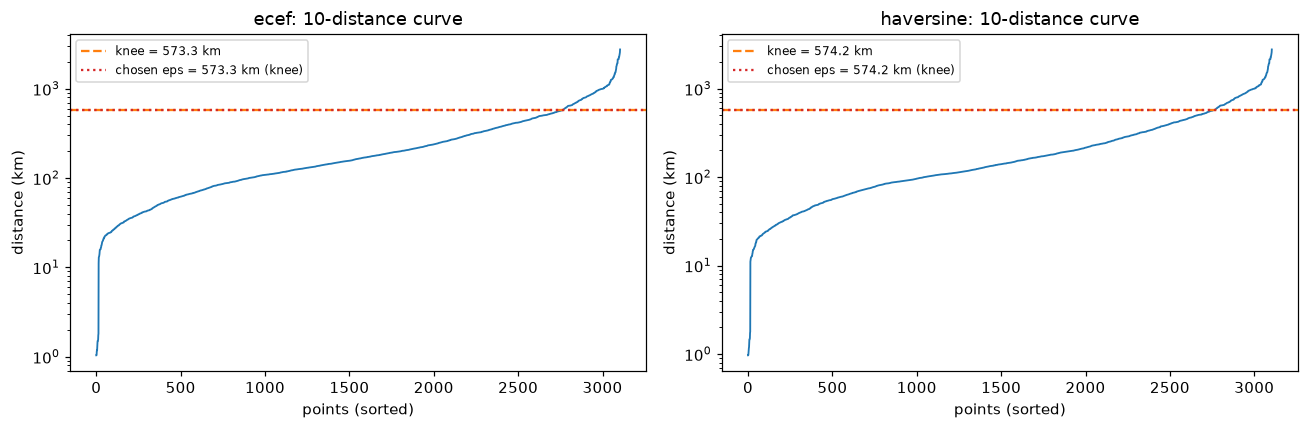

In [8]:
X_train = {v: to_space(train, v) for v in VARIANTS}
dbscan_runs = {}   # variant -> dict with everything we learn about it

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, variant in zip(axes, VARIANTS):
    kd = k_distance_km(X_train[variant], variant)
    knee_idx = find_knee(kd)
    knee_eps = float(kd[knee_idx])
    eps_km, status, sweep = choose_eps(X_train[variant], variant, knee_eps)
    dbscan_runs[variant] = {"knee_eps_km": knee_eps, "eps_km": eps_km, "eps_status": status, "sweep": sweep}

    ax.plot(kd, lw=1.2)
    ax.axhline(knee_eps, ls="--", c="tab:orange", label=f"knee = {knee_eps:.1f} km")
    ax.axhline(eps_km, ls=":", c="tab:red", label=f"chosen eps = {eps_km:.1f} km ({status})")
    ax.set(title=f"{variant}: {MIN_SAMPLES}-distance curve", xlabel="points (sorted)", ylabel="distance (km)", yscale="log")
    ax.legend(fontsize=8)
    print(f"{variant:9s}: knee eps = {knee_eps:7.1f} km -> chosen eps = {eps_km:7.1f} km [{status}]")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "k_distance_curves.png"), bbox_inches="tight")
plt.show()

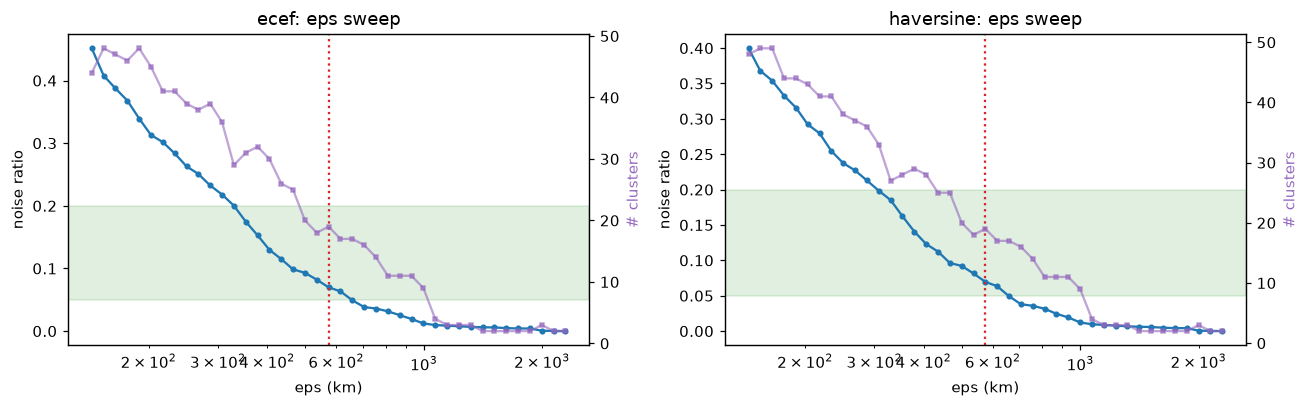

In [9]:
# How noise % and #clusters change with eps (shaded band = target 5-20% noise)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, variant in zip(axes, VARIANTS):
    sw, run = dbscan_runs[variant]["sweep"], dbscan_runs[variant]
    ax.plot(sw["eps_km"], sw["noise_ratio"], "o-", ms=3, label="noise ratio")
    ax.axhspan(*NOISE_BAND, color="green", alpha=0.12)
    ax.axvline(run["eps_km"], ls=":", c="tab:red")
    ax2 = ax.twinx()
    ax2.plot(sw["eps_km"], sw["n_clusters"], "s-", ms=3, c="tab:purple", alpha=0.6)
    ax2.set_ylabel("# clusters", color="tab:purple")
    ax.set(xscale="log", title=f"{variant}: eps sweep", xlabel="eps (km)", ylabel="noise ratio")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "eps_sweep.png"), bbox_inches="tight")
plt.show()

## 3. Fit on train, assign val/test (inductive DBSCAN)

sklearn's DBSCAN has no `.predict()`. Rule from the spec: a new point joins the cluster of its **nearest core point** if that point is within `eps`; otherwise it is noise (`-1`).

The "model" we save is a plain **dict** (not a custom class) so other notebooks can `joblib.load` it without needing this notebook's code. `assign_dbscan` is the predict function — Module 4 copies it.

`dist_to_nearest_fault_km` = distance to the nearest core point of *any* cluster (for training rows, excluding the row itself so train and val/test are measured the same way):
- `ecef`: straight-line 3D distance (includes depth difference)
- `haversine`: great-circle distance along the surface

In [10]:
def build_dbscan_model(db, X_fit, variant, eps_km):
    """Package a fitted DBSCAN + its core points + a 1-NN index over the core points."""
    v = VARIANTS[variant]
    core_idx = db.core_sample_indices_
    if len(core_idx) == 0:
        raise ValueError(f"[{variant}] DBSCAN found no core points - eps too small or min_samples too big.")
    core_points = X_fit[core_idx]
    nn = NearestNeighbors(n_neighbors=1, metric=v["metric"], algorithm=v["algorithm"]).fit(core_points)
    return {"variant": variant, "feature_cols": v["cols"], "metric": v["metric"],
            "km_per_unit": v["km_per_unit"], "eps_km": eps_km, "min_samples": MIN_SAMPLES,
            "dbscan": db, "core_points": core_points, "core_labels": db.labels_[core_idx], "core_nn": nn}


def assign_dbscan(df, model):
    """Out-of-sample DBSCAN: (cluster labels int32, distance to nearest core point in km)."""
    X = df[model["feature_cols"]].to_numpy(dtype=float)
    dist, idx = model["core_nn"].kneighbors(X)
    dist_km = dist[:, 0] * model["km_per_unit"]
    labels = np.where(dist_km <= model["eps_km"] + 1e-9, model["core_labels"][idx[:, 0]], -1)
    return labels.astype("int32"), dist_km


def train_dist_to_core_km(model, X_fit):
    """Training rows only: distance to the nearest core point that is NOT the row itself.
    Without this, every training core point would get distance 0 while val/test points never do."""
    core_idx = model["dbscan"].core_sample_indices_
    core_pos = np.full(len(X_fit), -1)
    core_pos[core_idx] = np.arange(len(core_idx))      # row -> its position among core points (-1 if not core)
    dist, idx = model["core_nn"].kneighbors(X_fit, n_neighbors=2)
    d = np.where(idx[:, 0] == core_pos, dist[:, 1], dist[:, 0])
    return d * model["km_per_unit"]


for variant, run in dbscan_runs.items():
    db = fit_dbscan(X_train[variant], run["eps_km"], variant)          # train ONLY
    model = build_dbscan_model(db, X_train[variant], variant, run["eps_km"])
    run["model"] = model
    run["labels"], run["dist_km"] = {}, {}
    for s, df in splits.items():
        labels, dist_km = assign_dbscan(df, model)
        if s == "train":
            # train keeps DBSCAN's own labels; the assign rule should agree almost everywhere
            agree = np.mean(labels == db.labels_)
            labels = db.labels_.astype("int32")
            dist_km = train_dist_to_core_km(model, X_train[variant])
        run["labels"][s], run["dist_km"][s] = labels, dist_km
    noise = {s: np.mean(run["labels"][s] == -1) for s in SPLITS}
    print(f"{variant:9s}: {len(set(db.labels_) - {-1}):3d} clusters | core pts {len(model['core_points']):5d} | "
          f"train-rule agreement {agree:.1%} | noise " + " ".join(f"{s}={noise[s]:.1%}" for s in SPLITS))

ecef     :  19 clusters | core pts  2764 | train-rule agreement 99.9% | noise train=7.0% val=8.0% test=7.5%
haversine:  19 clusters | core pts  2767 | train-rule agreement 99.9% | noise train=7.0% val=7.7% test=7.5%


## 3b. Pick the better DBSCAN variant
Silhouette and Davies-Bouldin are computed on non-noise training points. To make the two variants comparable, both are scored in a **Euclidean km space**:
- `ecef` → its own 3D ECEF coordinates
- `haversine` → surface ECEF (depth = 0), i.e. the space it actually clustered in

Both metrics are unit-free ratios. **Rule:** among variants with train noise inside the band, highest silhouette wins (`FORCE_DBSCAN_VARIANT` overrides).

In [11]:
def eval_space(df, variant):
    """Euclidean km coordinates in which a variant's clusters are scored."""
    if variant == "ecef":
        return df[ECEF_COLS].to_numpy(dtype=float)
    lat, lon, R = df["lat_rad"].to_numpy(), df["lon_rad"].to_numpy(), EARTH_RADIUS_KM
    return np.column_stack([R * np.cos(lat) * np.cos(lon), R * np.cos(lat) * np.sin(lon), R * np.sin(lat)])


def cluster_quality(X, labels):
    """Silhouette (higher better, -1..1) and Davies-Bouldin (lower better) on non-noise points."""
    mask = labels != -1
    n_clusters = len(np.unique(labels[mask]))
    out = {"n_clusters": n_clusters, "noise_ratio": float(np.mean(~mask)),
           "silhouette": np.nan, "davies_bouldin": np.nan}
    if n_clusters >= 2 and mask.sum() > n_clusters:
        Xm, lm = X[mask], labels[mask]
        out["silhouette"] = float(silhouette_score(Xm, lm, sample_size=min(SILHOUETTE_SAMPLE, len(lm)),
                                                   random_state=RANDOM_STATE))
        out["davies_bouldin"] = float(davies_bouldin_score(Xm, lm))
    return out


comparison = pd.DataFrame({
    v: {**cluster_quality(eval_space(train, v), run["labels"]["train"]),
        "eps_km": run["eps_km"], "eps_status": run["eps_status"]}
    for v, run in dbscan_runs.items()
}).T
comparison["in_noise_band"] = comparison["noise_ratio"].astype(float).between(*NOISE_BAND)

if FORCE_DBSCAN_VARIANT:
    DBSCAN_VARIANT = FORCE_DBSCAN_VARIANT
else:
    pool = comparison[comparison["in_noise_band"]]
    pool = pool if len(pool) else comparison          # nobody in band -> compare all
    DBSCAN_VARIANT = pool["silhouette"].astype(float).idxmax()

ALT_VARIANT = [v for v in VARIANTS if v != DBSCAN_VARIANT][0]
print(f"Selected DBSCAN variant: {DBSCAN_VARIANT}")
comparison

Selected DBSCAN variant: ecef


,n_clusters,noise_ratio,silhouette,davies_bouldin,eps_km,eps_status,in_noise_band
ecef,19,0.069887,0.108124,0.649156,573.308627,knee,True
haversine,19,0.069565,0.105869,0.65084,574.156819,knee,True


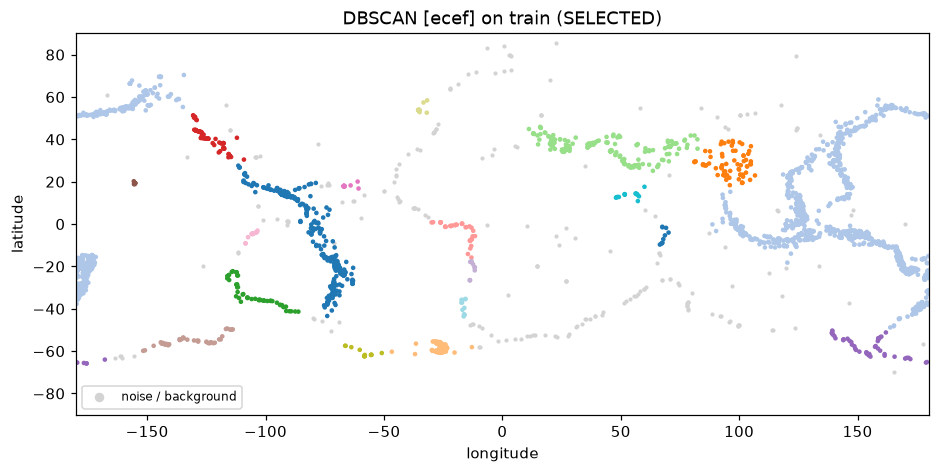

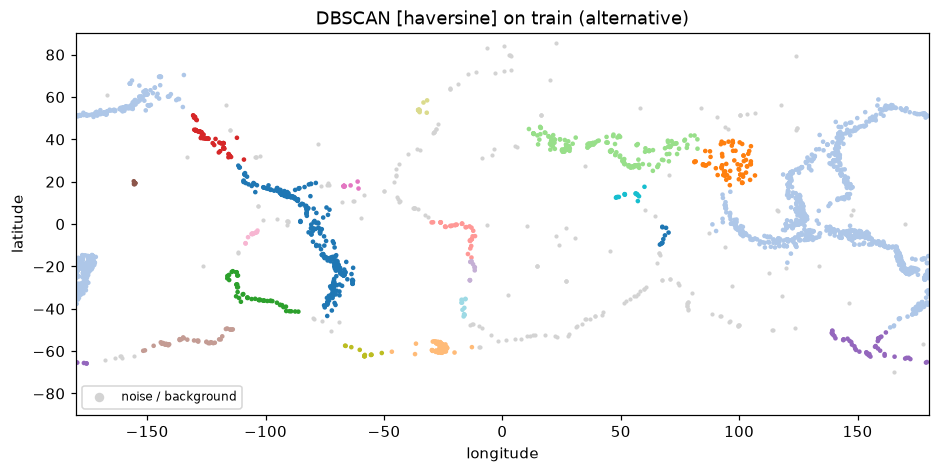

In [12]:
# tab20 minus its two greys, so no cluster can be confused with grey noise
CLUSTER_CMAP = matplotlib.colors.ListedColormap([c for i, c in enumerate(plt.cm.tab20.colors) if i not in (14, 15)])
N_COLORS = CLUSTER_CMAP.N


def plot_cluster_map(df, labels, title, path):
    """Lon/lat map: clusters coloured, noise in light grey."""
    fig, ax = plt.subplots(figsize=(10, 4.5))
    noise = labels == -1
    ax.scatter(df.loc[noise, "longitude"], df.loc[noise, "latitude"], s=3, c="lightgrey", label="noise / background")
    ax.scatter(df.loc[~noise, "longitude"], df.loc[~noise, "latitude"], s=4, c=labels[~noise] % N_COLORS, cmap=CLUSTER_CMAP)
    ax.set(xlabel="longitude", ylabel="latitude", title=title, xlim=(-180, 180), ylim=(-90, 90))
    ax.legend(loc="lower left", fontsize=8, markerscale=3)
    fig.savefig(path, bbox_inches="tight")
    plt.show()


for v in (DBSCAN_VARIANT, ALT_VARIANT):
    tag = "SELECTED" if v == DBSCAN_VARIANT else "alternative"
    plot_cluster_map(train, dbscan_runs[v]["labels"]["train"], f"DBSCAN [{v}] on train ({tag})",
                     os.path.join(FIG_DIR, f"dbscan_map_{v}.png"))

## 4. Gaussian Mixture Model (EM)

Inputs: ECEF (`x, y, z`) **+** sensor PCA columns. These are in very different units (thousands of km vs. ~±3), so a `StandardScaler` (fit on train) puts them on equal footing; otherwise location would completely dominate.

Sweep K over the spec grid, fit with EM, record BIC and AIC. **K\* = argmin BIC** (BIC penalises extra components harder than AIC, so it picks a more compact model; AIC's choice is reported too).

**Regularisation (`GMM_REG_COVAR`):** with sklearn's default (1e-6), some components shrank onto a handful of training points: train log-likelihood +1.33 vs val −1.04, and BIC just kept falling to the end of the grid. Adding 0.05 to each covariance diagonal keeps every component a "real" blob, gives BIC a true minimum inside the grid, and makes `gmm_*` features behave the same on train and val/test. Val log-likelihood is printed for monitoring only; it is **not** used to choose K.

In [13]:
GMM_FEATURES = ECEF_COLS + PCA_COLS
assert not set(GMM_FEATURES) & set(TARGET_COLS), "Target leakage into GMM features!"

gmm_scaler = StandardScaler().fit(train[GMM_FEATURES])                  # train ONLY
Z = {s: gmm_scaler.transform(df[GMM_FEATURES]) for s, df in splits.items()}

gmm_rows, gmm_fits = [], {}
for k in GMM_K_GRID:
    if k >= len(Z["train"]):
        print(f"skip K={k}: more components than training points")
        continue
    g = GaussianMixture(n_components=k, covariance_type=GMM_COVARIANCE, n_init=GMM_N_INIT,
                        max_iter=GMM_MAX_ITER, reg_covar=GMM_REG_COVAR,
                        random_state=RANDOM_STATE).fit(Z["train"])
    gmm_fits[k] = g
    gmm_rows.append({"k": k, "bic": g.bic(Z["train"]), "aic": g.aic(Z["train"]),
                     "train_mean_ll": g.score(Z["train"]), "val_mean_ll": g.score(Z["val"]),
                     "converged": g.converged_})
    r = gmm_rows[-1]
    print(f"K={k:3d}  BIC={r['bic']:10.1f}  AIC={r['aic']:10.1f}  "
          f"train_ll={r['train_mean_ll']:6.2f}  val_ll={r['val_mean_ll']:6.2f}  converged={g.converged_}")

gmm_sweep = pd.DataFrame(gmm_rows)
BEST_K_BIC = int(gmm_sweep.loc[gmm_sweep["bic"].idxmin(), "k"])
BEST_K_AIC = int(gmm_sweep.loc[gmm_sweep["aic"].idxmin(), "k"])
GMM_K = BEST_K_BIC
gmm = gmm_fits[GMM_K]
print(f"\nBIC picks K={BEST_K_BIC}, AIC picks K={BEST_K_AIC}. Using K*={GMM_K}.")
if GMM_K == max(gmm_sweep["k"]):
    warnings.warn(f"K*={GMM_K} is the largest K tried: BIC may still be falling. Consider extending GMM_K_GRID.")

K=  5  BIC=   38667.3  AIC=   37827.7  train_ll= -6.05  val_ll= -6.39  converged=True


K= 10  BIC=   33772.9  AIC=   32087.5  train_ll= -5.08  val_ll= -5.44  converged=True


K= 15  BIC=   31581.9  AIC=   29050.8  train_ll= -4.54  val_ll= -5.01  converged=True


K= 20  BIC=   31321.6  AIC=   27944.8  train_ll= -4.32  val_ll= -4.74  converged=True


K= 25  BIC=   31514.9  AIC=   27292.4  train_ll= -4.17  val_ll= -4.60  converged=True


K= 30  BIC=   31929.3  AIC=   26861.1  train_ll= -4.06  val_ll= -4.54  converged=True


K= 40  BIC=   32865.7  AIC=   26106.1  train_ll= -3.84  val_ll= -4.37  converged=True

BIC picks K=20, AIC picks K=40. Using K*=20.


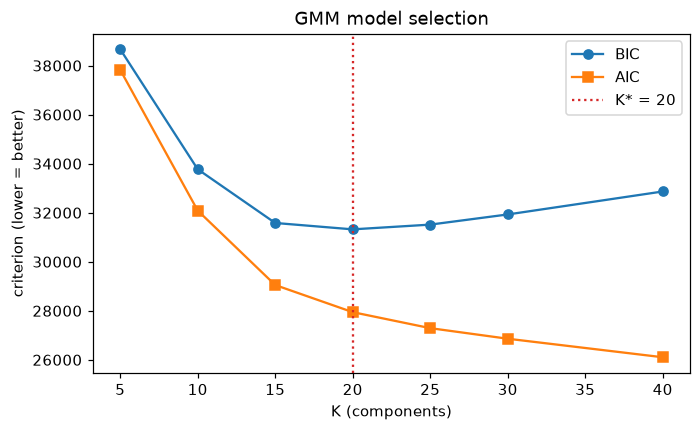

In [14]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(gmm_sweep["k"], gmm_sweep["bic"], "o-", label="BIC")
ax.plot(gmm_sweep["k"], gmm_sweep["aic"], "s-", label="AIC")
ax.axvline(GMM_K, ls=":", c="tab:red", label=f"K* = {GMM_K}")
ax.set(xlabel="K (components)", ylabel="criterion (lower = better)", title="GMM model selection")
ax.legend()
fig.savefig(os.path.join(FIG_DIR, "gmm_bic_aic.png"), bbox_inches="tight")
plt.show()

In [15]:
def gmm_outputs(Zs, gmm):
    """Posterior probabilities, hard cluster (argmax) and per-event log density."""
    proba = gmm.predict_proba(Zs)                       # P(component k | event), rows sum to 1
    return {"proba": proba,
            "cluster": proba.argmax(axis=1).astype("int32"),
            "log_likelihood": gmm.score_samples(Zs)}   # log p(x): high = event sits in a dense region


gmm_out = {s: gmm_outputs(Z[s], gmm) for s in SPLITS}
for s in SPLITS:
    print(f"{s:5s}: mean log-likelihood {gmm_out[s]['log_likelihood'].mean():8.3f} | "
          f"components used {len(np.unique(gmm_out[s]['cluster']))}/{GMM_K}")

GMM_TRAIN_VAL_GAP = gmm_out["train"]["log_likelihood"].mean() - gmm_out["val"]["log_likelihood"].mean()
print(f"train - val log-likelihood gap: {GMM_TRAIN_VAL_GAP:.2f} (warn above {GMM_MAX_TRAIN_VAL_GAP})")
if GMM_TRAIN_VAL_GAP > GMM_MAX_TRAIN_VAL_GAP:
    warnings.warn("GMM looks overfit (train density much higher than val). Consider a larger GMM_REG_COVAR.")

train: mean log-likelihood   -4.320 | components used 20/20
val  : mean log-likelihood   -4.740 | components used 20/20
test : mean log-likelihood   -4.368 | components used 19/20
train - val log-likelihood gap: 0.42 (warn above 1.0)


## 5. Cluster evaluation & geological sanity
Final metrics for the selected DBSCAN and the GMM, a GMM map, a 3D view, and a markdown report.
*(Optional, not implemented: comparison with the PB2002 plate-boundary dataset.)*

DBSCAN: {'n_clusters': 19, 'noise_ratio': 0.0699, 'silhouette': 0.1081, 'davies_bouldin': 0.6492}
GMM   : {'n_clusters': 20, 'noise_ratio': 0.0, 'silhouette': 0.267, 'davies_bouldin': 1.459}
Noise ratio by split: {'train': '7.0%', 'val': '8.0%', 'test': '7.5%'}


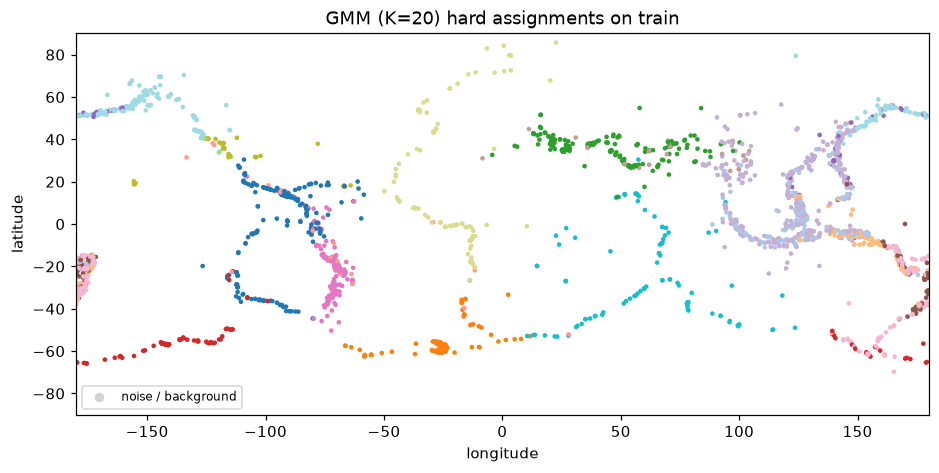

In [16]:
sel = dbscan_runs[DBSCAN_VARIANT]
dbscan_metrics = cluster_quality(eval_space(train, DBSCAN_VARIANT), sel["labels"]["train"])
gmm_metrics = cluster_quality(Z["train"], gmm_out["train"]["cluster"])   # GMM has no noise label
noise_by_split = {s: float(np.mean(sel["labels"][s] == -1)) for s in SPLITS}

print("DBSCAN:", {k: round(v, 4) if isinstance(v, float) else v for k, v in dbscan_metrics.items()})
print("GMM   :", {k: round(v, 4) if isinstance(v, float) else v for k, v in gmm_metrics.items()})
print("Noise ratio by split:", {s: f"{r:.1%}" for s, r in noise_by_split.items()})
lo, hi = NOISE_BAND
if not lo <= noise_by_split["train"] <= hi:
    warnings.warn(f"Train noise ratio {noise_by_split['train']:.1%} is outside the {lo:.0%}-{hi:.0%} target band.")

plot_cluster_map(train, gmm_out["train"]["cluster"], f"GMM (K={GMM_K}) hard assignments on train",
                 os.path.join(FIG_DIR, "gmm_map.png"))

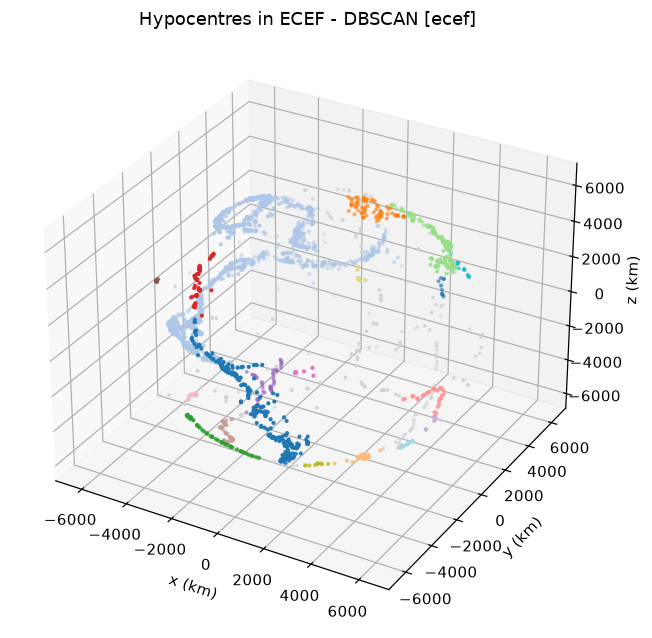

In [17]:
# 3D view of hypocentres in ECEF space (km), coloured by the selected DBSCAN cluster
lab = sel["labels"]["train"]
fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(projection="3d")
noise = lab == -1
ax.scatter(*train.loc[noise, ECEF_COLS].to_numpy().T, s=2, c="lightgrey")
ax.scatter(*train.loc[~noise, ECEF_COLS].to_numpy().T, s=3, c=lab[~noise] % N_COLORS, cmap=CLUSTER_CMAP)
ax.set(xlabel="x (km)", ylabel="y (km)", zlabel="z (km)", title=f"Hypocentres in ECEF - DBSCAN [{DBSCAN_VARIANT}]")
fig.savefig(os.path.join(FIG_DIR, "dbscan_3d_ecef.png"), bbox_inches="tight")
plt.show()

In [18]:
def fmt(x):
    return f"{x:.4f}" if isinstance(x, float) else str(x)

report = f"""# Module 2 - Clustering Validation Report
{"> **MOCK DATA** - generated because Module 1 outputs were missing. Not scientifically meaningful." if USING_MOCK else ""}

## Data
| split | rows |
|---|---|
""" + "".join(f"| {s} | {len(splits[s])} |\n" for s in SPLITS) + f"""
## DBSCAN variant comparison (train, non-noise points)
| variant | eps (km) | eps status | clusters | noise | silhouette | Davies-Bouldin |
|---|---|---|---|---|---|---|
""" + "".join(
    f"| {v}{' (selected)' if v == DBSCAN_VARIANT else ''} | {r['eps_km']:.1f} | {r['eps_status']} | "
    f"{r['n_clusters']} | {r['noise_ratio']:.1%} | {fmt(r['silhouette'])} | {fmt(r['davies_bouldin'])} |\n"
    for v, r in comparison.iterrows()) + f"""
min_samples = {MIN_SAMPLES}; target noise band = {NOISE_BAND[0]:.0%}-{NOISE_BAND[1]:.0%}.
Noise ratio by split (selected): """ + ", ".join(f"{s} {r:.1%}" for s, r in noise_by_split.items()) + f"""

## GMM
Features: {", ".join(GMM_FEATURES)} (standardised). Covariance: {GMM_COVARIANCE}. reg_covar: {GMM_REG_COVAR}.

| K | BIC | AIC | train mean log-lik | val mean log-lik | converged |
|---|---|---|---|---|---|
""" + "".join(f"| {int(r.k)} | {r.bic:.1f} | {r.aic:.1f} | {r.train_mean_ll:.3f} | {r.val_mean_ll:.3f} | {r.converged} |\n"
              for r in gmm_sweep.itertuples()) + f"""
BIC picks K={BEST_K_BIC}, AIC picks K={BEST_K_AIC}. **Selected K* = {GMM_K}.**
Train - val log-likelihood gap at K*: {GMM_TRAIN_VAL_GAP:.3f}.
Silhouette (hard assignments) = {fmt(gmm_metrics['silhouette'])}, Davies-Bouldin = {fmt(gmm_metrics['davies_bouldin'])}.

## Figures
See `figures/`: k_distance_curves, eps_sweep, dbscan_map_*, gmm_bic_aic, gmm_map, dbscan_3d_ecef.
"""
with open(os.path.join(REPORTS_DIR, "clustering_validation_report.md"), "w", encoding="utf-8") as f:
    f.write(report)
print("Report written to", os.path.join(REPORTS_DIR, "clustering_validation_report.md"))

Report written to ./reports\clustering_validation_report.md


## 6. Build & export the Augmented dataset
Base columns are copied untouched; new columns are appended (contract: `module2/TODO.md` §6.1). Row order and `event_id`s stay identical to Base so Modules 3/4 can line them up.

In [19]:
def build_augmented(base_df, db_labels, db_dist_km, g_out):
    """Base columns + DBSCAN + GMM feature columns (with the contract's dtypes)."""
    new = {
        "dbscan_cluster": db_labels.astype("int32"),
        "is_background_noise": (db_labels == -1).astype("int32"),
        "dist_to_nearest_fault_km": db_dist_km.astype("float64"),
        "gmm_cluster": g_out["cluster"].astype("int32"),
        "gmm_log_likelihood": g_out["log_likelihood"].astype("float64"),
    }
    for k in range(g_out["proba"].shape[1]):
        new[f"gmm_prob_{k}"] = g_out["proba"][:, k].astype("float64")
    return pd.concat([base_df.reset_index(drop=True), pd.DataFrame(new)], axis=1)


augmented = {s: build_augmented(splits[s], sel["labels"][s], sel["dist_km"][s], gmm_out[s]) for s in SPLITS}
NEW_COLS = [c for c in augmented["train"].columns if c not in splits["train"].columns]
PROB_COLS = [f"gmm_prob_{k}" for k in range(GMM_K)]

### 6b. Validation checklist (spec §7)

In [20]:
for s in SPLITS:
    aug, base = augmented[s], splits[s]
    # 1. probability invariant
    max_dev = np.abs(aug[PROB_COLS].sum(axis=1) - 1).max()
    assert max_dev < 1e-5, f"{s}: GMM probabilities don't sum to 1 (max deviation {max_dev})"
    # rows unchanged and aligned with Base
    assert len(aug) == len(base) and (aug["event_id"].values == base["event_id"].values).all(), f"{s}: row mismatch"
    assert aug[NEW_COLS].notna().all().all(), f"{s}: NaNs in new columns"
# 3. no target leakage into any clusterer
for v in VARIANTS.values():
    assert not set(v["cols"]) & set(TARGET_COLS)
assert not set(GMM_FEATURES) & set(TARGET_COLS)
# 2. background tremor ratio (warn, not fail: real data decides)
print(f"Train noise ratio: {noise_by_split['train']:.1%} (target {NOISE_BAND[0]:.0%}-{NOISE_BAND[1]:.0%})")
print("All checks passed. New columns:", NEW_COLS[:5], f"+ {len(PROB_COLS)} gmm_prob_* columns")

Train noise ratio: 7.0% (target 5%-20%)
All checks passed. New columns: ['dbscan_cluster', 'is_background_noise', 'dist_to_nearest_fault_km', 'gmm_cluster', 'gmm_log_likelihood'] + 20 gmm_prob_* columns


In [21]:
# --- Save datasets ---
for s in SPLITS:
    path = os.path.join(DATA_AUG_DIR, f"{s}_augmented.parquet")
    augmented[s].to_parquet(path, index=False)
    print(f"saved {path}  {augmented[s].shape}")

# --- Save models (plain dicts of sklearn objects: loadable without this notebook) ---
joblib.dump(sel["model"], os.path.join(ARTIFACTS_DIR, "dbscan_model.joblib"))
joblib.dump(dbscan_runs[ALT_VARIANT]["model"], os.path.join(ARTIFACTS_DIR, f"dbscan_model_alt_{ALT_VARIANT}.joblib"))
joblib.dump({"gmm": gmm, "scaler": gmm_scaler, "feature_cols": GMM_FEATURES, "k": GMM_K},
            os.path.join(ARTIFACTS_DIR, "gmm_model.joblib"))

with open(os.path.join(ARTIFACTS_DIR, "bic_aic_curves.json"), "w") as f:
    json.dump({"k": gmm_sweep["k"].tolist(), "bic": gmm_sweep["bic"].tolist(), "aic": gmm_sweep["aic"].tolist(),
               "best_k_bic": BEST_K_BIC, "best_k_aic": BEST_K_AIC, "selected_k": GMM_K}, f, indent=2)

with open(os.path.join(ARTIFACTS_DIR, "dbscan_variant_comparison.json"), "w") as f:
    json.dump({"selected": DBSCAN_VARIANT, "min_samples": MIN_SAMPLES,
               "variants": {v: {k: (None if (isinstance(x, float) and np.isnan(x)) else
                                    (x.item() if hasattr(x, "item") else x))
                                for k, x in row.items()} for v, row in comparison.iterrows()}}, f, indent=2)
print("Artifacts saved to", ARTIFACTS_DIR, "->", sorted(os.listdir(ARTIFACTS_DIR)))

saved ../data/augmented\train_augmented.parquet  (3105, 71)
saved ../data/augmented\val_augmented.parquet  (665, 71)
saved ../data/augmented\test_augmented.parquet  (666, 71)
Artifacts saved to ./artifacts -> ['bic_aic_curves.json', 'dbscan_model.joblib', 'dbscan_model_alt_haversine.joblib', 'dbscan_variant_comparison.json', 'gmm_model.joblib']


### 6c. How downstream notebooks reuse the models
```python
import joblib, numpy as np
db = joblib.load("module2/artifacts/dbscan_model.joblib")
dist, idx = db["core_nn"].kneighbors(df[db["feature_cols"]].to_numpy(float))
dist_km = dist[:, 0] * db["km_per_unit"]
dbscan_cluster = np.where(dist_km <= db["eps_km"], db["core_labels"][idx[:, 0]], -1)

g = joblib.load("module2/artifacts/gmm_model.joblib")
Zs = g["scaler"].transform(df[g["feature_cols"]])
proba = g["gmm"].predict_proba(Zs)
```

In [22]:
print("Mode:", "MOCK" if USING_MOCK else "REAL")
print("DBSCAN variant:", DBSCAN_VARIANT, f"(eps={sel['eps_km']:.1f} km, min_samples={MIN_SAMPLES})")
print("GMM K*:", GMM_K)
augmented["train"][["event_id"] + NEW_COLS[:5] + PROB_COLS[:3]].head()

Mode: REAL
DBSCAN variant: ecef (eps=573.3 km, min_samples=10)
GMM K*: 20


,event_id,dbscan_cluster,is_background_noise,dist_to_nearest_fault_km,gmm_cluster,gmm_log_likelihood,gmm_prob_0,gmm_prob_1,gmm_prob_2
0,usc000p27i,0,0,31.614670,12,-3.340399,2.502331e-02,3.830127e-42,2.515523e-08
1,us60008bj6,1,0,6.403973,13,-1.294158,1.482529e-27,3.382936e-04,1.620023e-33
2,us6000le2y,1,0,7.867061,8,-6.765858,4.083407e-41,3.363659e-19,3.258800e-66
3,us6000ldsf,1,0,21.382196,19,-7.984301,3.640448e-51,2.131175e-04,8.498428e-44
4,us7000clbu,1,0,335.649312,9,-3.692824,2.503854e-22,2.451942e-03,5.012626e-57
